# Praktikum 2 - Klasifikasi Iris dengan Keras

Praktikum ini membangun JST menggunakan Keras untuk mengklasifikasikan dataset Iris ke dalam tiga kelas. Eksperimen yang dilakukan:

1. Baseline: hidden layer 10 dan 8 neuron dengan aktivasi ReLU.
2. Mengubah jumlah neuron hidden layer (16-8 dan 32-16).
3. Membandingkan aktivasi Sigmoid dan ReLU pada konfigurasi yang sama.

## 1. Import Library dan Seed

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 2. Load Dataset dan Split Data

Dataset Iris dibagi 80% data latih dan 20% data uji dengan stratifikasi agar proporsi setiap kelas tetap seimbang. Label diubah menjadi one-hot encoding.

In [2]:
iris = load_iris()
X = iris.data
y_int = iris.target

X_train, X_test, y_train_int, y_test_int = train_test_split(
    X, y_int, test_size=0.2, random_state=SEED, stratify=y_int
)

encoder = OneHotEncoder(sparse_output=False)
y_train = encoder.fit_transform(y_train_int.reshape(-1, 1))
y_test = encoder.transform(y_test_int.reshape(-1, 1))

print('Ukuran data latih:', X_train.shape)
print('Ukuran data uji  :', X_test.shape)
print('Kelas            :', iris.target_names)

Ukuran data latih: (120, 4)
Ukuran data uji  : (30, 4)
Kelas            : ['setosa' 'versicolor' 'virginica']


## 3. Fungsi Membangun Model

In [3]:
def build_model(hidden_1=10, hidden_2=8, activation='relu'):
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(hidden_1, activation=activation, input_shape=(4,)),
        tf.keras.layers.Dense(hidden_2, activation=activation),
        tf.keras.layers.Dense(3, activation='softmax'),
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )

    return model

## 4. Fungsi Training dan Evaluasi

Seed diatur ulang sebelum setiap model dibuat agar perbandingan antar konfigurasi adil.

In [4]:
def run_experiment(name, hidden_1, hidden_2, activation,
                   epochs=50, batch_size=8):
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(hidden_1, hidden_2, activation)

    start = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
    )
    training_time = time.perf_counter() - start

    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

    return {
        'name': name,
        'hidden_1': hidden_1,
        'hidden_2': hidden_2,
        'activation': activation,
        'history': history.history,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'training_time': training_time,
    }

## 5. Menjalankan Eksperimen

In [5]:
configs = [
    ('Baseline 10-8 ReLU', 10, 8, 'relu'),
    ('Hidden 16-8 ReLU', 16, 8, 'relu'),
    ('Hidden 32-16 ReLU', 32, 16, 'relu'),
    ('Baseline 10-8 Sigmoid', 10, 8, 'sigmoid'),
]

results = []

for name, hidden_1, hidden_2, activation in configs:
    result = run_experiment(name, hidden_1, hidden_2, activation)
    results.append(result)

    print(f"{name}: test loss={result['test_loss']:.4f}, "
          f"test accuracy={result['test_accuracy']:.4f}, "
          f"waktu={result['training_time']:.2f} s")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Baseline 10-8 ReLU: test loss=0.2216, test accuracy=1.0000, waktu=5.64 s
Hidden 16-8 ReLU: test loss=0.1880, test accuracy=1.0000, waktu=5.04 s
Hidden 32-16 ReLU: test loss=0.0995, test accuracy=0.9667, waktu=4.65 s
Baseline 10-8 Sigmoid: test loss=0.5758, test accuracy=0.7667, waktu=5.90 s


## 6. Tabel Perbandingan

In [6]:
tabel = pd.DataFrame([
    {
        'Konfigurasi': r['name'],
        'Hidden': f"{r['hidden_1']}-{r['hidden_2']}",
        'Aktivasi': r['activation'].capitalize(),
        'Test Loss': round(r['test_loss'], 4),
        'Test Accuracy': round(r['test_accuracy'], 4),
        'Waktu (s)': round(r['training_time'], 2),
    }
    for r in results
])

tabel

,Konfigurasi,Hidden,Aktivasi,Test Loss,Test Accuracy,Waktu (s)
0,Baseline 10-8 ReLU,10-8,Relu,0.2216,1.0000,5.64
1,Hidden 16-8 ReLU,16-8,Relu,0.1880,1.0000,5.04
2,Hidden 32-16 ReLU,32-16,Relu,0.0995,0.9667,4.65
3,Baseline 10-8 Sigmoid,10-8,Sigmoid,0.5758,0.7667,5.90


## 7. Grafik Training

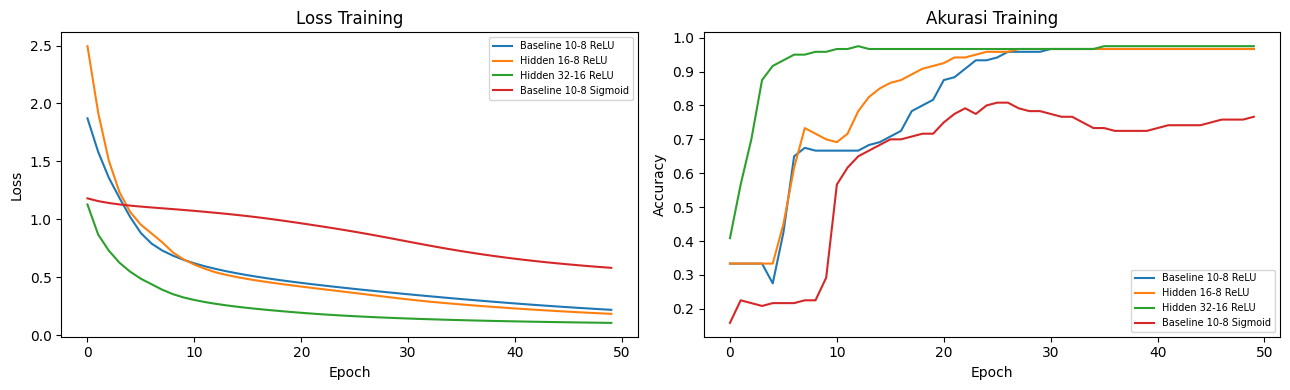

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for r in results:
    axes[0].plot(r['history']['loss'], label=r['name'])
    axes[1].plot(r['history']['accuracy'], label=r['name'])

axes[0].set_title('Loss Training')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=7)

axes[1].set_title('Akurasi Training')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

## 8. Analisis Hasil

Seluruh angka pada bagian ini diambil dari output aktual notebook.

| Konfigurasi | Hidden | Aktivasi | Test Loss | Test Accuracy | Waktu (s) |
|---|---|---:|---:|---:|---:|
| Baseline 10-8 | 10-8 | ReLU | 0.2216 | 1.0000 | 5.64 |
| Hidden 16-8 | 16-8 | ReLU | 0.1880 | 1.0000 | 5.04 |
| Hidden 32-16 | 32-16 | ReLU | 0.0995 | 0.9667 | 4.65 |
| Baseline 10-8 | 10-8 | Sigmoid | 0.5758 | 0.7667 | 5.90 |

1. **ReLU baseline mencapai akurasi sempurna.** Model 10-8 ReLU memperoleh akurasi data uji 1.0000 dengan loss 0.2216.
2. **Menambah neuron menurunkan loss.** Konfigurasi 16-8 menurunkan loss menjadi 0.1880 dengan akurasi tetap 1.0000. Konfigurasi 32-16 memberi loss terendah, yaitu 0.0995.
3. **Loss terendah tidak selalu berarti akurasi tertinggi.** Model 32-16 memiliki loss paling kecil, tetapi akurasinya 0.9667 karena satu dari 30 data uji salah klasifikasi. Sebaliknya, model 16-8 dengan loss lebih tinggi tetap mencapai akurasi 1.0000.
4. **Sigmoid jauh lebih buruk daripada ReLU pada konfigurasi yang sama.** Akurasi turun dari 1.0000 menjadi 0.7667 dan loss naik dari 0.2216 menjadi 0.5758. Pada jaringan dengan dua hidden layer, Sigmoid mengalami gradien yang lebih kecil sehingga konvergensi lebih lambat dalam 50 epoch.
5. **Waktu training relatif setara.** Rentangnya 4.65-5.90 detik. Perbedaan ini kecil dan dapat dipengaruhi oleh variasi beban CPU, bukan semata-mata ukuran model.
6. **Catatan.** Data uji hanya 30 sampel, sehingga satu kesalahan berarti 3.33 poin persentase. Perbedaan akurasi perlu dibaca dengan hati-hati.